In [59]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter
import shutil
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import EfficientNetB0

import warnings
warnings.filterwarnings("ignore")

# Set random seed untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = '/kaggle/input/datasets/aullyanadinek/dataset-penyakit-daun-jagung/data'

CLASSES = sorted(os.listdir(DATA_DIR))

# a) EDA & Preprocessing

In [60]:
NUM_CLASSES = len(CLASSES)

print(f"Kelas ditemukan : {CLASSES}")
print(f"Jumlah kelas : {NUM_CLASSES}")

Kelas ditemukan : ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
Jumlah kelas : 4


## Check Format File

In [61]:
formats = set()
for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    for file in os.listdir(class_folder):
        ext = file.split('.')[-1].lower()
        formats.add(ext)

print("Format dalam dataset:", formats)

Format dalam dataset: {'jpg', 'jpeg'}


Dataset mengandung 2 ekstensi file: .jpg dan .jpeg. Keduanya adalah format JPEG yang identik secara teknis, sehingga tidak diperlukan konversi format.

## Class Distribution

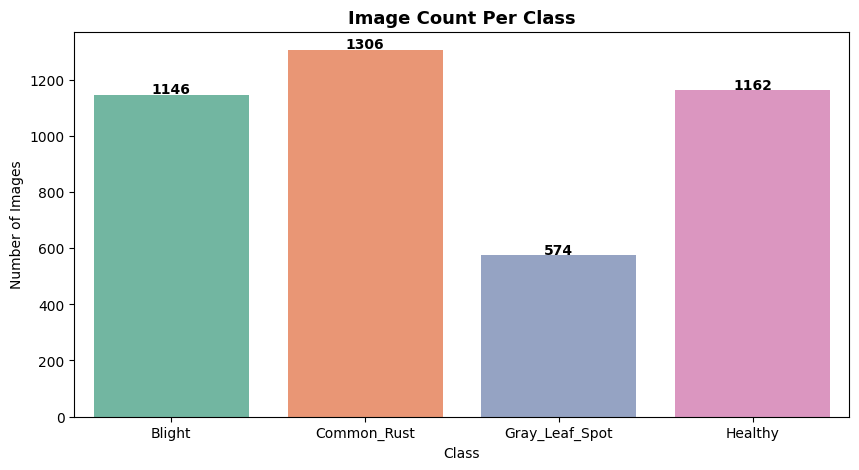

In [62]:
class_counts = {}
for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    image_count = len(os.listdir(class_folder))
    class_counts[c] = image_count

plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="Set2")
plt.title('Image Count Per Class', fontsize=13, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Number of Images')
for i, v in enumerate(class_counts.values()):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.show()

Terlihat bahwa data kita imbalance dimana Gray_Leaf_Spot hanya sebanyak 574 images, sedangkan yang lain mencapai lebih dari 1000 images

## Image Dimension

## Sample Images per Class

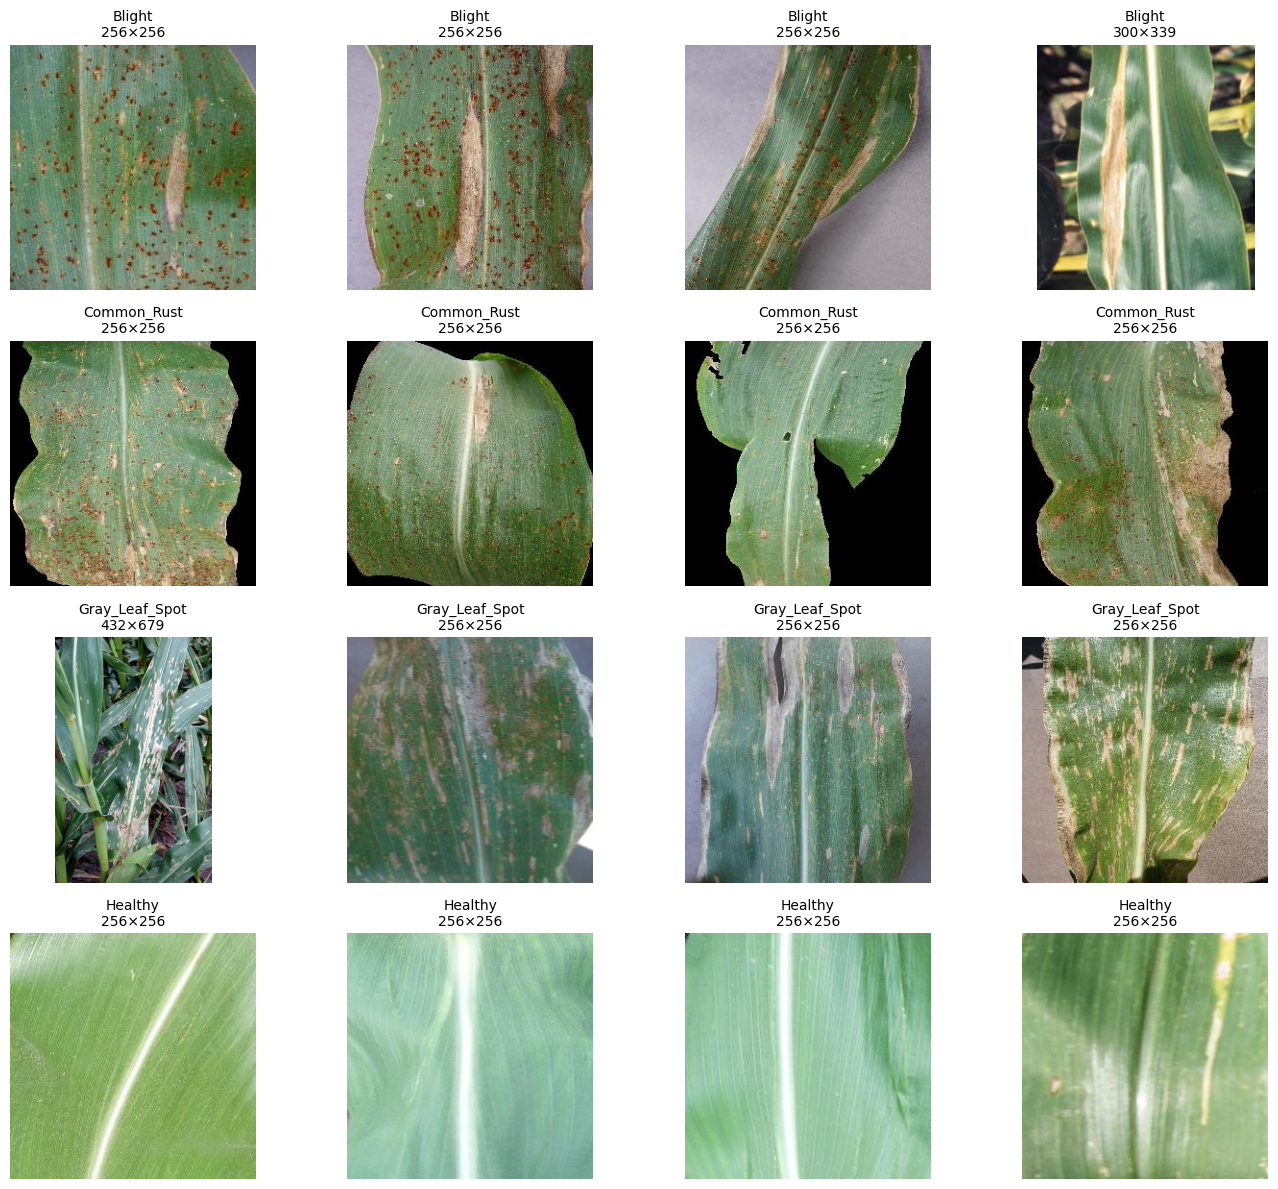

In [63]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(14, 3*len(CLASSES)))

for i, c in enumerate(CLASSES):
    class_folder = os.path.join(DATA_DIR, c)
    files = random.sample(os.listdir(class_folder), 4)
    for j, f in enumerate(files):
        img = Image.open(os.path.join(class_folder, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(f'{c}\n{img.size[0]}×{img.size[1]}', fontsize=10)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

In [64]:
print("Image Dimensions Per Class:\n")

for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    sizes = []
    for file in os.listdir(class_folder):
        if file.lower().endswith(('.jpg', '.jpeg')):
            with Image.open(os.path.join(class_folder, file)) as img:
                sizes.append(img.size)

    size_counts = Counter(sizes)
    print(f"Class '{c}':")
    for size, count in size_counts.items():
        print(f"  - {size} : {count} images")
    if len(size_counts) > 1:
        print("  Different image sizes detected.\n")
    else:
        print("  All images have the same size.\n")

Image Dimensions Per Class:

Class 'Blight':
  - (256, 256) : 985 images
  - (900, 1200) : 2 images
  - (400, 300) : 4 images
  - (500, 500) : 1 images
  - (525, 699) : 1 images
  - (188, 317) : 1 images
  - (640, 640) : 1 images
  - (635, 417) : 1 images
  - (256, 385) : 1 images
  - (882, 1632) : 1 images
  - (400, 400) : 1 images
  - (650, 1024) : 1 images
  - (360, 640) : 1 images
  - (788, 371) : 1 images
  - (250, 200) : 1 images
  - (1024, 768) : 3 images
  - (960, 540) : 2 images
  - (1200, 1600) : 5 images
  - (640, 427) : 1 images
  - (1920, 1080) : 1 images
  - (180, 347) : 1 images
  - (401, 341) : 1 images
  - (450, 612) : 1 images
  - (1936, 1296) : 1 images
  - (400, 267) : 1 images
  - (1024, 473) : 1 images
  - (751, 1001) : 1 images
  - (606, 404) : 1 images
  - (618, 463) : 1 images
  - (1024, 416) : 1 images
  - (2592, 1936) : 1 images
  - (640, 480) : 1 images
  - (239, 454) : 1 images
  - (780, 511) : 1 images
  - (505, 283) : 1 images
  - (594, 374) : 1 images
  

In [65]:
data = []
for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    for f in os.listdir(class_folder):
        if f.lower().endswith(('.jpg', '.jpeg')):
            with Image.open(os.path.join(class_folder, f)) as img:
                w, h = img.size
                data.append({
                    'class': c,
                    'width': w,
                    'height': h,
                    'aspect_ratio': round(w / h, 3),
                    'resolution': w * h
                })

df_img = pd.DataFrame(data)

square_count = ((df_img['aspect_ratio'] >= 0.95) & (df_img['aspect_ratio'] <= 1.05)).sum()
print(f"Gambar dengan aspect ratio ~1.0 (square): {square_count} dari {len(df_img)} "
      f"({square_count/len(df_img)*100:.2f}%)")

unique_res = df_img.groupby(['width', 'height']).size().reset_index(name='count').sort_values('count', ascending=False)
print("\nTop 10 resolution paling sering muncul:")
unique_res.head(10)

Gambar dengan aspect ratio ~1.0 (square): 3865 dari 4188 (92.29%)

Top 10 resolution paling sering muncul:


,width,height,count
12,256,256,3852
212,1024,768,8
260,3264,2448,7
162,675,1200,7
171,750,350,5
223,1200,1600,5
221,1200,900,5
101,480,320,4
238,1500,1125,4
151,640,480,4


In [66]:
print("Statistik Width, Height, Aspect Ratio, Resolution:")
df_img[['width', 'height', 'aspect_ratio', 'resolution']].describe()

Statistik Width, Height, Aspect Ratio, Resolution:


,width,height,aspect_ratio,resolution
count,4188.000000,4188.000000,4188.000000,4.188000e+03
mean,307.536533,297.906160,1.024139,1.568553e+05
std,285.716933,253.138674,0.163395,8.118375e+05
min,180.000000,116.000000,0.288000,3.387200e+04
25%,256.000000,256.000000,1.000000,6.553600e+04
50%,256.000000,256.000000,1.000000,6.553600e+04
75%,256.000000,256.000000,1.000000,6.553600e+04
max,5184.000000,5184.000000,3.748000,1.791590e+07


In [67]:
print("Statistik per Class:\n")
summary = df_img.groupby('class').agg(
    count=('width', 'count'),
    mean_width=('width', 'mean'),
    mean_height=('height', 'mean'),
    mean_ar=('aspect_ratio', 'mean'),
    min_ar=('aspect_ratio', 'min'),
    max_ar=('aspect_ratio', 'max'),
    mean_res=('resolution', 'mean')
).round(2)
summary

Statistik per Class:



,count,mean_width,mean_height,mean_ar,min_ar,max_ar,mean_res
class,,,,,,,
Blight,1146,345.40,336.75,1.03,0.29,2.95,235493.00
Common_Rust,1306,319.27,303.95,1.03,0.37,3.75,170438.16
Gray_Leaf_Spot,574,309.59,291.43,1.04,0.34,2.39,153815.46
Healthy,1162,256.00,256.00,1.00,1.00,1.00,65536.00


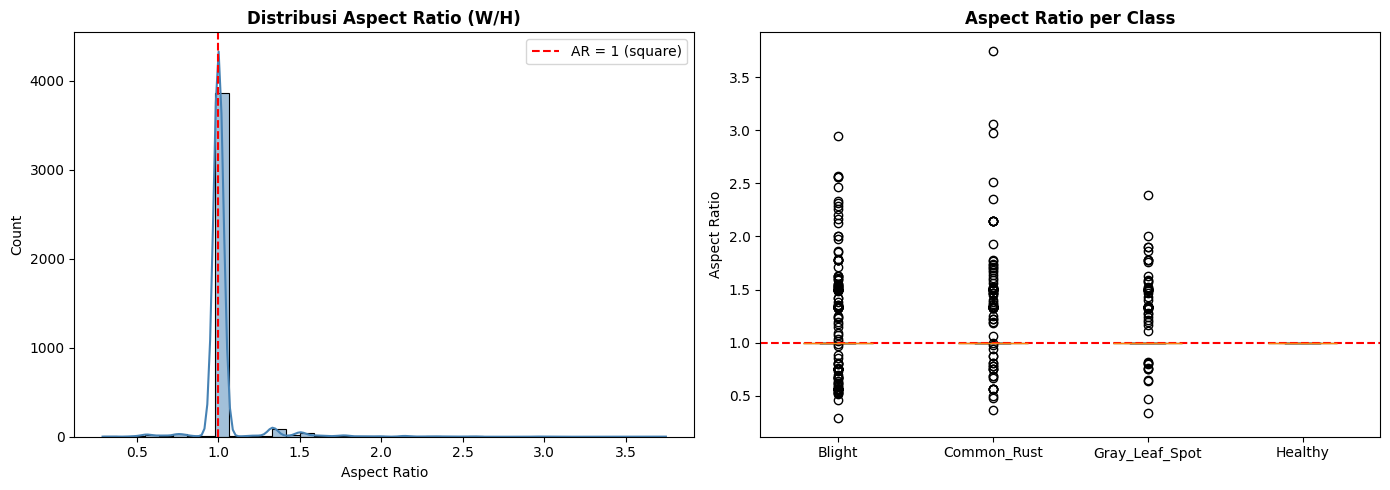

In [ ]:
fig_top, axes_top = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_img['aspect_ratio'], bins=40, kde=True, ax=axes_top[0], color='steelblue')
axes_top[0].axvline(1.0, color='red', linestyle='--', label='AR = 1 (square)')
axes_top[0].set_title('Distribusi Aspect Ratio (W/H)', fontweight='bold')
axes_top[0].set_xlabel('Aspect Ratio')
axes_top[0].legend()

data_to_plot = [df_img[df_img['class'] == c]['aspect_ratio'] for c in CLASSES]
axes_top[1].boxplot(data_to_plot, labels=CLASSES, patch_artist=True, 
                    boxprops=dict(facecolor='#d5e8d4', color='#4d7c58'))
axes_top[1].axhline(1.0, color='red', linestyle='--')
axes_top[1].set_title('Aspect Ratio per Class', fontweight='bold')
axes_top[1].tick_params(axis='x')
axes_top[1].set_ylabel('Aspect Ratio')

plt.tight_layout()
plt.show()

Analisis distribusi aspect ratio menunjukkan bahwa sebagian besar citra dalam dataset memiliki proporsi mendekati persegi (AR = 1.0). Namun, pada beberapa kelas penyakit seperti Blight, Common Rust, dan Gray Leaf Spot, ditemukan variasi yang cukup signifikan, termasuk adanya pencilan dengan nilai AR > 3.0. Hal ini mengindikasikan keberadaan citra dengan dimensi yang sangat tidak proporsional.

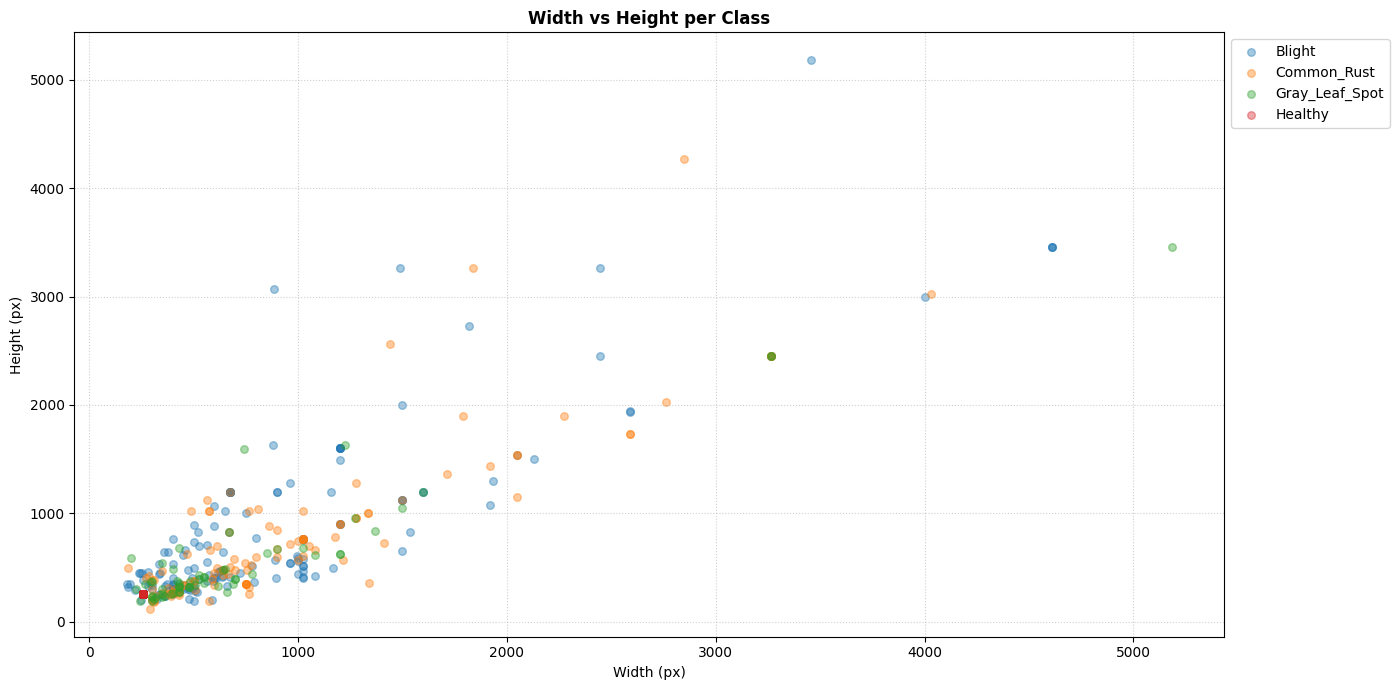

In [ ]:
plt.figure(figsize=(14, 7))

for c in CLASSES:
    sub = df_img[df_img['class'] == c]
    plt.scatter(sub['width'], sub['height'], alpha=0.4, label=c, s=30)

plt.title('Width vs Height per Class', fontweight='bold')
plt.xlabel('Width (px)')
plt.ylabel('Height (px)')
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.grid(True, linestyle=':', alpha=0.6) 

plt.tight_layout()
plt.show()

Visualisasi Width vs Height per kelas menunjukkan bahwa mayoritas dataset terkonsentrasi pada resolusi di bawah 1000 piksel dengan pola distribusi linier, yang mengonfirmasi bahwa sebagian besar citra memiliki proporsi dimensi yang konsisten. Meskipun demikian, terdapat beberapa outliers dengan resolusi tinggi mencapai di atas 4000 piksel pada kelas Blight dan Common Rust.

## Mode Warna pada Dataset

In [70]:
modes = []

for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    for f in os.listdir(class_folder):
        with Image.open(os.path.join(class_folder, f)) as img:
            modes.append(img.mode)

print(f"Mode warna yang ditemukan: {dict(Counter(modes))}")

Mode warna yang ditemukan: {'RGB': 4183, 'RGBA': 4, 'CMYK': 1}


Dataset mayoritas menggunakan mode RGB (4183 gambar / 99.88%), namun ditemukan beberapa file dengan mode berbeda:
- 4 gambar RGBA (RGB + alpha channel transparansi)
- 1 gambar CMYK (format print, 4 channel)

Namun, saat data dimuat menggunakan image_dataset_from_directory, semua gambar otomatis dikonversi menjadi format RGB dengan 3 channel. Dengan demikian, seluruh data sudah seragam dan siap digunakan sebagai input model sehingga tidak perlu preprocessing tambahan.

In [71]:
print("File non-RGB:\n")

for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    for f in os.listdir(class_folder):
        with Image.open(os.path.join(class_folder, f)) as img:
            if img.mode != 'RGB':
                print(f"  {c}/{f} → mode: {img.mode}")

File non-RGB:

  Common_Rust/Corn_Common_Rust (1289).jpg → mode: RGBA
  Common_Rust/Corn_Common_Rust (1275).jpg → mode: RGBA
  Common_Rust/Corn_Common_Rust (1295).jpg → mode: RGBA
  Gray_Leaf_Spot/Corn_Gray_Spot (32).jpg → mode: CMYK
  Gray_Leaf_Spot/Corn_Gray_Spot (1).jpg → mode: RGBA


## RGB Histogram per Classes

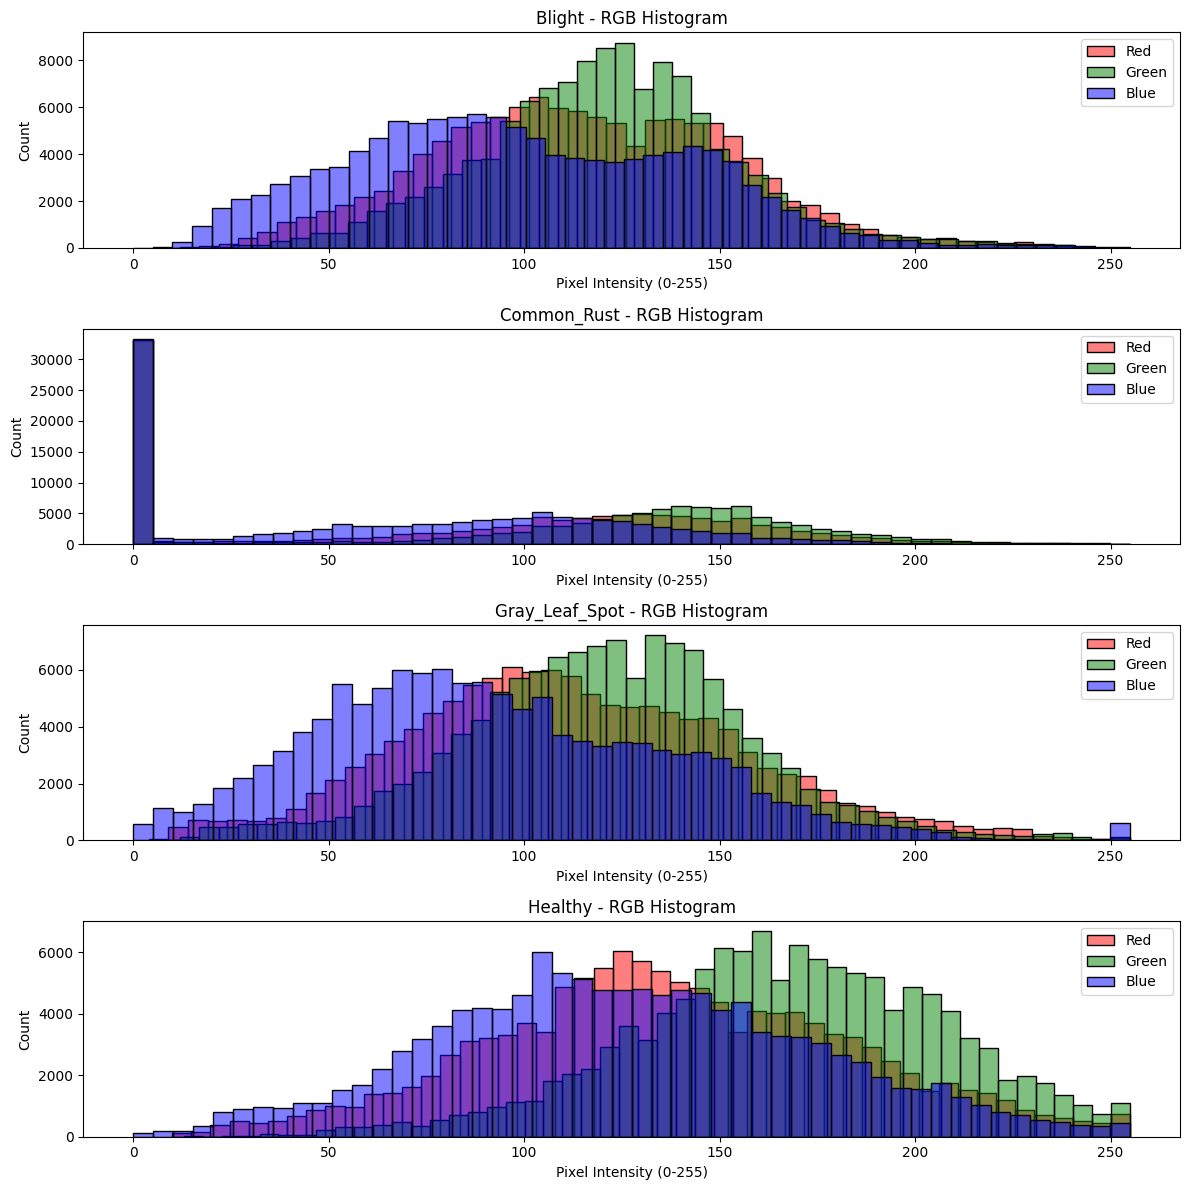

In [72]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(12, 3*len(CLASSES)))

for i, c in enumerate(CLASSES):
    class_folder = os.path.join(DATA_DIR, c)
    files = random.sample(os.listdir(class_folder), 30)

    r_pixels, g_pixels, b_pixels = [], [], []
    for f in files:
        img = np.array(Image.open(os.path.join(class_folder, f)).convert('RGB').resize((64, 64)))
        r_pixels.append(img[:,:,0].flatten())
        g_pixels.append(img[:,:,1].flatten())
        b_pixels.append(img[:,:,2].flatten())

    sns.histplot(np.concatenate(r_pixels), bins=50, color='red', alpha=0.5, label='Red', ax=axes[i])
    sns.histplot(np.concatenate(g_pixels), bins=50, color='green', alpha=0.5, label='Green', ax=axes[i])
    sns.histplot(np.concatenate(b_pixels), bins=50, color='blue', alpha=0.5, label='Blue', ax=axes[i])
    axes[i].set_title(f'{c} - RGB Histogram')
    axes[i].set_xlabel('Pixel Intensity (0-255)')
    axes[i].legend()

plt.tight_layout()
plt.show()

Histogram RGB menunjukkan bahwa daun **Healthy** cenderung didominasi oleh kanal **Green** pada intensitas menengah hingga tinggi, yang merepresentasikan kandungan klorofil. Sebaliknya, infeksi penyakit menyebabkan perubahan karakteristik warna secara signifikan. Pada kelas **Common Rust**, terlihat peningkatan intensitas rendah (mendekati 0) yang mengindikasikan adanya bercak karat berwarna gelap. Sementara itu, pada kelas **Gray Leaf Spot** dan **Blight**, terjadi pergeseran distribusi pada kanal **Red** dan **Blue**, yang mencerminkan gejala pemucatan atau nekrosis, ditandai dengan munculnya warna kelabu hingga kecokelatan pada permukaan daun.


# Split Dataset

In [73]:
SPLIT_DIR = '/kaggle/working/dataset_split'
TRAIN_DIR = os.path.join(SPLIT_DIR, 'train')
VAL_DIR   = os.path.join(SPLIT_DIR, 'val')
TEST_DIR  = os.path.join(SPLIT_DIR, 'test')

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for d in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for c in CLASSES:
        os.makedirs(os.path.join(d, c), exist_ok=True)

split_summary = []

for c in CLASSES:
    class_folder = os.path.join(DATA_DIR, c)
    files = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg'))]
    
    trainval_files, test_files = train_test_split(
        files, test_size=0.15, random_state=SEED
    )
    
    train_files, val_files = train_test_split(
        trainval_files, test_size=15/85, random_state=SEED
    )
    
    for f in train_files:
        shutil.copy(os.path.join(class_folder, f), os.path.join(TRAIN_DIR, c, f))
    for f in val_files:
        shutil.copy(os.path.join(class_folder, f), os.path.join(VAL_DIR, c, f))
    for f in test_files:
        shutil.copy(os.path.join(class_folder, f), os.path.join(TEST_DIR, c, f))
    
    split_summary.append({
        'class': c,
        'total': len(files),
        'train': len(train_files),
        'val': len(val_files),
        'test': len(test_files)
    })

df_split = pd.DataFrame(split_summary)
df_split.loc['TOTAL'] = ['-', df_split['total'].sum(), df_split['train'].sum(),
                         df_split['val'].sum(), df_split['test'].sum()]
df_split

,class,total,train,val,test
0,Blight,1146,802,172,172
1,Common_Rust,1306,914,196,196
2,Gray_Leaf_Spot,574,401,86,87
3,Healthy,1162,812,175,175
TOTAL,-,4188,2929,629,630


In [74]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    color_mode='rgb',          
    shuffle=True,
    seed=SEED
)

val_ds = image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    color_mode='rgb',          
    shuffle=False
)

test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    color_mode='rgb',          
    shuffle=False
)

print(f"\nClass names: {train_ds.class_names}")

Found 2929 files belonging to 4 classes.
Found 629 files belonging to 4 classes.
Found 630 files belonging to 4 classes.

Class names: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


# Preprocessing

In [75]:
AUTOTUNE = tf.data.AUTOTUNE

# Normalisasi menjadi [0,1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomContrast(0.1),
], name='data_augmentation')

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)
train_ds = train_ds.cache().prefetch(AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
).cache().prefetch(AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
).cache().prefetch(AUTOTUNE)

for images, labels in train_ds.take(1):
    print(f"Batch images shape : {images.shape}")
    print(f"Batch labels shape : {labels.shape}")
    print(f"Pixel value range  : [{images.numpy().min():.3f}, {images.numpy().max():.3f}]")

Batch images shape : (32, 224, 224, 3)
Batch labels shape : (32, 4)
Pixel value range  : [0.000, 1.038]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.22399455..1.0208212].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.018389404..1.0045222].


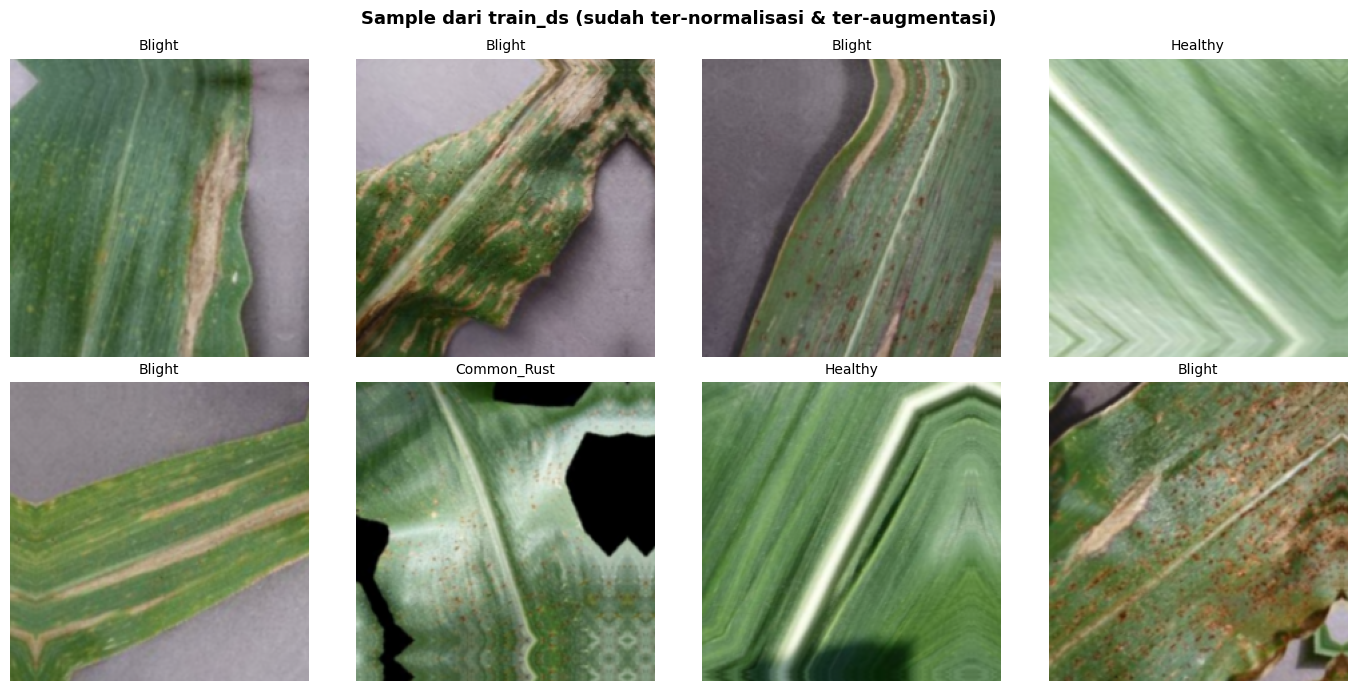

In [76]:
# Ambil 1 batch dari train_ds (sudah ter-augmentasi)
for images, labels in train_ds.take(1):
    plt.figure(figsize=(14, 7))
    for i in range(8):
        plt.subplot(2, 4, i+1)
        plt.imshow(images[i].numpy())
        plt.title(f'{CLASSES[np.argmax(labels[i].numpy())]}', fontsize=10)
        plt.axis('off')
    plt.suptitle('Sample dari train_ds (sudah ter-normalisasi & ter-augmentasi)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    break

# b) Baseline Model

In [139]:
tf.keras.utils.set_random_seed(42)

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    # Conv1: 11x11, stride 4, 96 filters -> 54x54x96
    layers.Conv2D(96, kernel_size=(11, 11), strides=4, padding='valid', activation='relu'),
    layers.MaxPooling2D(pool_size=(3, 3), strides=2),
    
    # Conv2: 5x5, pad 2, 256 filters -> 26x26x256
    layers.Conv2D(256, kernel_size=(5, 5), strides=1, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(3, 3), strides=2),
    
    # Conv3, Conv4, Conv5: 3x3, pad 1
    layers.Conv2D(384, kernel_size=(3, 3), strides=1, padding='same', activation='relu'),
    layers.Conv2D(384, kernel_size=(3, 3), strides=1, padding='same', activation='relu'),
    layers.Conv2D(256, kernel_size=(3, 3), strides=1, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(3, 3), strides=2),
    
    # Flatten
    layers.Flatten(),
    
    # FC1 + FC2 dengan dropout 0.5
    layers.Dense(4096, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4096, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(NUM_CLASSES, activation='softmax')
])

baseline_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 4)              │        16,388 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,763,396 (178.39 MB)

 Trainable params: 46,763,396 (178.39 MB)

 Non-trainable params: 0 (0.00 B)

In [140]:
tf.keras.utils.set_random_seed(42)

baseline_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.F1Score(average='macro', name='f1_macro')   
    ]
)

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=1
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 96ms/step - accuracy: 0.4318 - f1_macro: 0.3383 - loss: 2.3562 - val_accuracy: 0.5374 - val_f1_macro: 0.3642 - val_loss: 0.9087
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.5281 - f1_macro: 0.4230 - loss: 1.0374 - val_accuracy: 0.4944 - val_f1_macro: 0.3380 - val_loss: 1.0117
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.5427 - f1_macro: 0.4430 - loss: 0.9979 - val_accuracy: 0.6232 - val_f1_macro: 0.4789 - val_loss: 0.8834
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.6650 - f1_macro: 0.5399 - loss: 0.8138 - val_accuracy: 0.7250 - val_f1_macro: 0.5839 - val_loss: 0.6510
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.7407 - f1_macro: 0.6218 - loss: 0.6766 - val_accuracy: 0.7393 - val_f1_macro: 0.6036 - val_loss: 0.6137
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.7438 - f1_macro: 0.6269 - loss: 0.6496 - val_accuracy: 0.8172 - val_f1_macro: 0.6616 - va

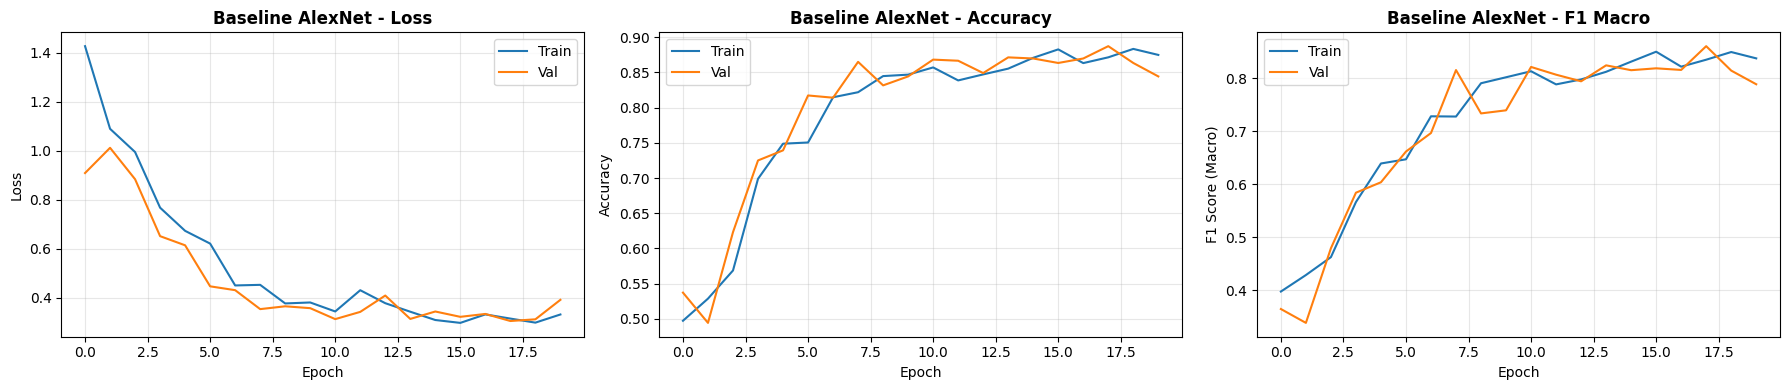

Train Accuracy : 0.8747
Val Accuracy   : 0.8442
Train Loss     : 0.3313
Val Loss       : 0.3912
Train F1 Macro : 0.8376
Val F1 Macro   : 0.7887


In [141]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Loss ---
axes[0].plot(history_baseline.history['loss'], label='Train')
axes[0].plot(history_baseline.history['val_loss'], label='Val')
axes[0].set_title('Baseline AlexNet - Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Accuracy ---
axes[1].plot(history_baseline.history['accuracy'], label='Train')
axes[1].plot(history_baseline.history['val_accuracy'], label='Val')
axes[1].set_title('Baseline AlexNet - Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)


# --- F1 Macro ---
axes[2].plot(history_baseline.history['f1_macro'], label='Train')
axes[2].plot(history_baseline.history['val_f1_macro'], label='Val')
axes[2].set_title('Baseline AlexNet - F1 Macro', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1 Score (Macro)')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Train Accuracy : {history_baseline.history['accuracy'][-1]:.4f}")
print(f"Val Accuracy   : {history_baseline.history['val_accuracy'][-1]:.4f}")
print(f"Train Loss     : {history_baseline.history['loss'][-1]:.4f}")
print(f"Val Loss       : {history_baseline.history['val_loss'][-1]:.4f}")
print(f"Train F1 Macro : {history_baseline.history['f1_macro'][-1]:.4f}")
print(f"Val F1 Macro   : {history_baseline.history['val_f1_macro'][-1]:.4f}")

Model baseline AlexNet menunjukkan tren konvergensi yang cukup stabil pada awal epoch, namun mulai mengalami fluktuasi minor pada data validasi setelah melewati epoch ke-15. Hal ini mengindikasikan bahwa model mulai mencapai titik saturasi dan menunjukkan gejala overfitting ringan, di mana kemampuan generalisasi model (Val F1: 0.7887) masih tertinggal dibandingkan performa pada data training. Ketidakstabilan ini kemungkinan besar disebabkan oleh keterbatasan model dalam mengekstraksi fitur yang lebih mendalam, terutama pada kelas-kelas yang memiliki kemiripan visual. 

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8302 - f1_macro: 0.5197 - loss: 0.5014
Test Loss     : 0.4428
Test Accuracy : 0.8429
Test F1 Macro : 0.7982
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Classification Report:
                precision    recall  f1-score   support

        Blight     0.7264    0.8488    0.7828       172
   Common_Rust     0.9503    0.8776    0.9125       196
Gray_Leaf_Spot     0.6667    0.4598    0.5442        87
       Healthy     0.9202    0.9886    0.9532       175

      accuracy                         0.8429       630
     macro avg     0.8159    0.7937    0.7982       630
  weighted avg     0.8416    0.8429    0.8375       630



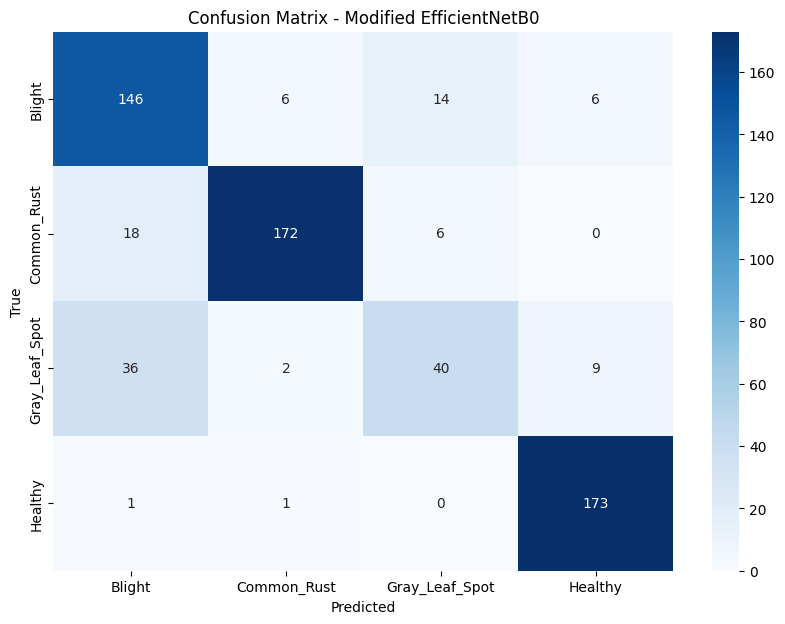

In [ ]:
test_loss_base, test_accuracy_base, test_f1_base = baseline_model.evaluate(test_ds, verbose=1)
print(f"Test Loss     : {test_loss_base:.4f}")
print(f"Test Accuracy : {test_accuracy_base:.4f}")
print(f"Test F1 Macro : {test_f1_base:.4f}")

predictions_base = baseline_model.predict(test_ds, verbose=1)
predicted_labels_base = np.argmax(predictions_base, axis=1)

true_labels_base = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

print("\nClassification Report:")
print(classification_report(true_labels_base, predicted_labels_base, target_names=CLASSES, digits=4))

cm = confusion_matrix(true_labels_base, predicted_labels_base)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Baseline Model')
plt.show()

Berdasarkan hasil classification report, kelemahan utama terlihat pada kelas Gray Leaf Spot yang memiliki nilai recall sangat rendah, yaitu 0.4598. Nilai recall yang rendah ini menunjukkan bahwa model sering gagal mengenali kasus Gray Leaf Spot, dan cenderung salah mengklasifikasikannya sebagai penyakit lain seperti Blight atau bahkan sebagai daun sehat. Kondisi ini dipengaruhi oleh arsitektur AlexNet yang menggunakan kernel berukuran besar, sehingga kurang mampu menangkap detail tekstur halus yang menjadi pembeda antar pola bercak penyakit. Selain itu, fluktuasi pada grafik validasi di akhir epoch juga mencerminkan keterbatasan generalisasi model, yang mengalami kesulitan dalam membedakan fitur-fitur yang saling tumpang tindih (feature overlap) pada dataset daun jagung.

# c) Modified Model

Modifikasi yang dilakukan pada model adalah mengganti arsitektur dari AlexNet menjadi EfficientNetB0 dengan pendekatan *transfer learning*. Perubahan ini didasarkan pada beberapa pertimbangan utama. 

Pertama, ukuran dataset yang hanya sekitar 4000 gambar tidak sebanding jika menggunakan model besar seperti AlexNet yang memiliki sekitar 46,8 juta parameter, karena berisiko menyebabkan overfitting ketika dilatih dari awal. Sebagai gantinya, EfficientNetB0 yang memiliki sekitar 5 juta parameter dinilai lebih proporsional, sehingga lebih ringan dan stabil untuk proses training. 

Kedua, penggunaan *transfer learning* dengan bobot awal dari ImageNet memungkinkan model sudah memiliki kemampuan dasar dalam mengekstraksi fitur visual seperti tepi, tekstur, dan bentuk dari sekitar 1,2 juta gambar, sehingga model tidak perlu belajar dari nol dan dapat mencapai performa yang lebih baik dengan proses pelatihan yang lebih efisien. 

Ketiga, untuk mengatasi ketidakseimbangan data antara kelas Common Rust yang berjumlah 1306 gambar dan Gray Leaf Spot sebanyak 574 gambar, digunakan parameter *class_weight = 'balanced'* agar model memberikan perhatian lebih pada kelas minoritas dan mampu menghasilkan prediksi yang lebih adil terhadap kedua kelas.


In [81]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_counts = []
for c in CLASSES:
    n = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    class_counts.append(n)
    print(f"  {c}: {n}")

y_train_labels = np.concatenate([np.full(n, i) for i, n in enumerate(class_counts)])

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(CLASSES)),
    y=y_train_labels
)
class_weights = dict(enumerate(class_weights_array))

print("\nClass weights:")
for idx, w in class_weights.items():
    print(f"  {CLASSES[idx]}: {w:.4f}")

  Blight: 802
  Common_Rust: 914
  Gray_Leaf_Spot: 401
  Healthy: 812

Class weights:
  Blight: 0.9130
  Common_Rust: 0.8011
  Gray_Leaf_Spot: 1.8261
  Healthy: 0.9018


In [ ]:
tf.keras.utils.set_random_seed(42)

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

modified_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(255.0),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),                     
    layers.Dense(128, activation='relu',
                 kernel_regularizer=tf.keras.regularizers.l2(1e-4)), 
    layers.Dropout(0.5),                     
    layers.Dense(NUM_CLASSES, activation='softmax')
], name='EfficientNetB0_Modified_v2')

modified_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.F1Score(average='macro', name='f1_macro')
    ]
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history_modified = modified_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 49s 283ms/step - accuracy: 0.6711 - f1_macro: 0.6353 - loss: 0.8760 - val_accuracy: 0.9237 - val_f1_macro: 0.9039 - val_loss: 0.2665 - learning_rate: 0.0010
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8739 - f1_macro: 0.8499 - loss: 0.3892 - val_accuracy: 0.9237 - val_f1_macro: 0.9026 - val_loss: 0.2400 - learning_rate: 0.0010
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8911 - f1_macro: 0.8706 - loss: 0.3384 - val_accuracy: 0.9300 - val_f1_macro: 0.9098 - val_loss: 0.2217 - learning_rate: 0.0010
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9038 - f1_macro: 0.8847 - loss: 0.3138 - val_accuracy: 0.9285 - val_f1_macro: 0.9111 - val_loss: 0.2222 - learning_rate: 0.0010
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.9008 - f1_macro: 0.8817 - loss: 0.2933 - val_accuracy: 0.9380 - val_f1_macro: 0.9182 - val_loss: 0.2023 - learning_rate: 0.0010
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━

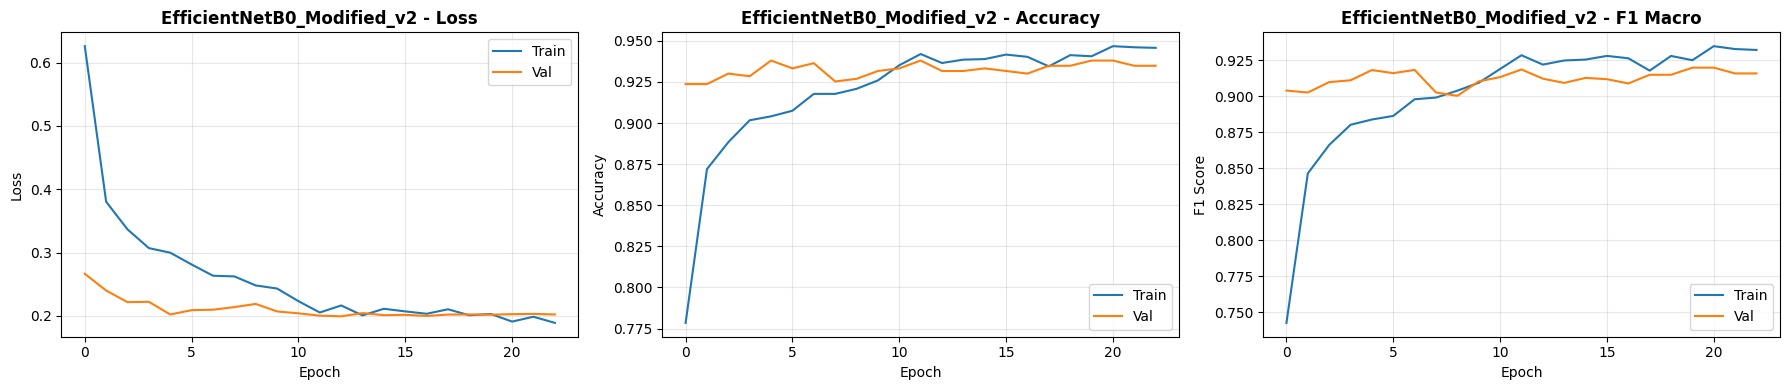

Train Accuracy   : 0.9457
Val Accuracy     : 0.9348
Train Loss       : 0.1890
Val Loss         : 0.2023
Train F1 Macro   : 0.9322
Val F1 Macro     : 0.9158


In [107]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(history_modified.history['loss'], label='Train')
axes[0].plot(history_modified.history['val_loss'], label='Val')
axes[0].set_title(f'{modified_model.name} - Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_modified.history['accuracy'], label='Train')
axes[1].plot(history_modified.history['val_accuracy'], label='Val')
axes[1].set_title(f'{modified_model.name} - Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(history_modified.history['f1_macro'], label='Train')
axes[2].plot(history_modified.history['val_f1_macro'], label='Val')
axes[2].set_title(f'{modified_model.name} - F1 Macro', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('F1 Score'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Train Accuracy   : {history_modified.history['accuracy'][-1]:.4f}")
print(f"Val Accuracy     : {history_modified.history['val_accuracy'][-1]:.4f}")
print(f"Train Loss       : {history_modified.history['loss'][-1]:.4f}")
print(f"Val Loss         : {history_modified.history['val_loss'][-1]:.4f}")
print(f"Train F1 Macro   : {history_modified.history['f1_macro'][-1]:.4f}")
print(f"Val F1 Macro     : {history_modified.history['val_f1_macro'][-1]:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 275ms/step - accuracy: 0.9269 - f1_macro: 0.5957 - loss: 0.2531
Test Loss     : 0.1957
Test Accuracy : 0.9397
Test F1 Macro : 0.9226
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 392ms/step

Classification Report:
                precision    recall  f1-score   support

        Blight     0.9064    0.9012    0.9038       172
   Common_Rust     0.9948    0.9796    0.9871       196
Gray_Leaf_Spot     0.8000    0.8276    0.8136        87
       Healthy     0.9830    0.9886    0.9858       175

      accuracy                         0.9397       630
     macro avg     0.9211    0.9242    0.9226       630
  weighted avg     0.9405    0.9397    0.9400       630



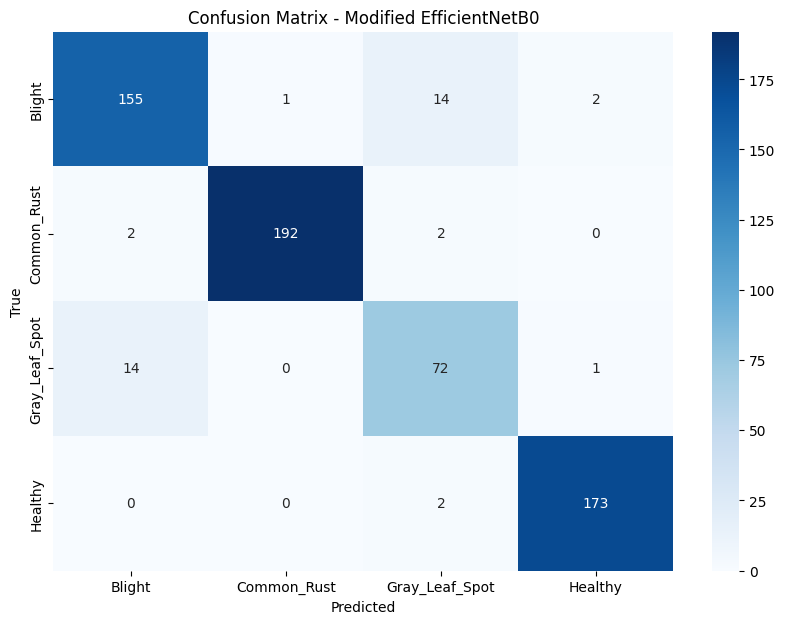

In [108]:
test_loss, test_accuracy, test_f1 = modified_model.evaluate(test_ds, verbose=1)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test F1 Macro : {test_f1:.4f}")

predictions = modified_model.predict(test_ds, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

true_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

print("\nClassification Report:")
print(classification_report(true_labels, predicted_labels, target_names=CLASSES, digits=4))

cm = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Modified EfficientNetB0')
plt.show()

Berbeda dengan baseline AlexNet, implementasi EfficientNet-B0 menunjukkan performa yang jauh lebih robust dan stabil. Hal ini tercermin dari kurva konvergensi yang lebih halus tanpa fluktuasi signifikan, serta peningkatan skor Val F1 Macro hingga mencapai 0.9158. Peningkatan paling signifikan terlihat pada kemampuan model dalam mendeteksi kelas yang sebelumnya sulit diklasifikasikan. Kelas Gray Leaf Spot, yang pada AlexNet memiliki recall rendah sebesar 0.45, mengalami peningkatan drastis menjadi 0.8276. Hasil ini menunjukkan bahwa EfficientNet-B0 mampu mengatasi kelemahan model sebelumnya dalam mengenali pola yang kompleks. Keberhasilan tersebut didukung oleh arsitektur EfficientNet yang memanfaatkan mekanisme compound scaling, sehingga mampu mengekstraksi fitur visual secara lebih mendalam dan diskriminatif. Dengan demikian, model menjadi lebih akurat dalam membedakan kelas-kelas yang memiliki kemiripan tekstur, seperti Blight dan Gray Leaf Spot, serta secara keseluruhan meningkatkan kemampuan generalisasi model.

# d) Evaluation

In [144]:
true_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

print("Predicting with Baseline AlexNet...")
pred_baseline = np.argmax(baseline_model.predict(test_ds, verbose=1), axis=1)

print("Predicting with Modified EfficientNetB0...")
pred_modified = np.argmax(modified_model.predict(test_ds, verbose=1), axis=1)

def get_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Macro)': precision_score(y_true, y_pred, average='macro'),
        'Recall (Macro)': recall_score(y_true, y_pred, average='macro'),
        'F1 Score (Macro)': f1_score(y_true, y_pred, average='macro'),
    }

comparison = pd.DataFrame({
    'Baseline AlexNet': get_metrics(true_labels, pred_baseline),
    'Modified EfficientNetB0': get_metrics(true_labels, pred_modified),
})
comparison['Improvement'] = comparison['Modified EfficientNetB0'] - comparison['Baseline AlexNet']
comparison = comparison.round(4)
comparison

Predicting with Baseline AlexNet...
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Predicting with Modified EfficientNetB0...
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step


,Baseline AlexNet,Modified EfficientNetB0,Improvement
Accuracy,0.8429,0.9397,0.0968
Precision (Macro),0.8159,0.9211,0.1052
Recall (Macro),0.7937,0.9242,0.1305
F1 Score (Macro),0.7982,0.9226,0.1244


Perbandingan performa antara kedua model menunjukkan bahwa transisi dari AlexNet ke EfficientNet-B0 memberikan peningkatan yang signifikan pada seluruh metrik evaluasi. Peningkatan paling menonjol terlihat pada Recall (Macro) yang naik sebesar 13,05%, menandakan bahwa EfficientNet-B0 jauh lebih efektif dalam mengurangi kesalahan *false negative* atau kegagalan dalam mendeteksi penyakit. Keunggulan ini didukung oleh arsitektur EfficientNet yang memanfaatkan MBConv dan mekanisme *Squeeze-and-Excitation*, sehingga mampu mengekstraksi dan menimbang fitur secara lebih adaptif, terutama pada detail tekstur halus seperti pada kelas Gray Leaf Spot yang sebelumnya sulit dikenali. Sebaliknya, AlexNet dengan filter berukuran besar cenderung kurang sensitif terhadap detail spasial penting dan lebih rentan terhadap overfitting karena jumlah parameternya yang jauh lebih besar.

Berdasarkan hasil tersebut, dapat disimpulkan bahwa penggunaan EfficientNet-B0 dengan *transfer learning* merupakan pendekatan yang lebih efektif dan efisien untuk klasifikasi penyakit daun jagung. Model ini mampu mencapai Test Accuracy sebesar 93,97% dan F1-Score sebesar 92,26%, serta menunjukkan performa yang stabil tanpa fluktuasi signifikan pada data validasi. Penerapan teknik seperti Global Average Pooling, Dropout, dan L2 Regularizer juga berkontribusi dalam menjaga generalisasi model agar tidak hanya menghafal data training.

Untuk pengembangan selanjutnya, performa model masih dapat ditingkatkan melalui beberapa langkah. Fine-tuning lanjutan dengan membuka (unfreeze) sebagian layer pada base model dapat membantu model menangkap fitur yang lebih spesifik. Selain itu, penggunaan teknik visualisasi seperti Grad-CAM dapat meningkatkan interpretabilitas model dengan menunjukkan area fokus saat prediksi. Dari sisi data, penambahan jumlah sampel khususnya pada kelas minoritas seperti Gray Leaf Spot menjadi langkah penting untuk mengatasi ketidakseimbangan. Teknik augmentasi lanjutan seperti MixUp dan CutMix juga dapat dipertimbangkan untuk meningkatkan variasi data dan memperkuat kemampuan generalisasi model.
